# Giai đoạn 5: mô hình cuối và đánh giá test
Phần A/B chỉ dùng train CV. Chỉ phần C mới đọc test_idx, sau khi quyết định mô hình đã được ghi cố định.

In [2]:
# Nạp thư viện và dữ liệu, chưa đọc test_idx
import sys,time,json
from pathlib import Path
import numpy as np,pandas as pd
import matplotlib.pyplot as plt,seaborn as sns
from sklearn.model_selection import StratifiedKFold,RandomizedSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support,classification_report,confusion_matrix,make_scorer,f1_score,recall_score,balanced_accuracy_score,matthews_corrcoef,accuracy_score
import joblib
sys.path.insert(0,str(Path('..').resolve()))
from src.data_prep import load_data,clean_data,get_feature_sets
from src.pipeline import make_pipeline
from src.evaluate import evaluate_cv
from src.logger import log_run,mark_invalid,find_duplicate_runs
RANDOM_STATE=42; CV=5
df,_=clean_data(load_data(Path('../data/RT_IOT2022'))); sets=get_feature_sets(df); features=sets['NO_SRC_PORT']; X=df.drop(columns=['Attack_type']); y=df['Attack_type']
split=np.load('../experiments/split_indices.npz'); train_idx=np.sort(split['train_idx']); X_train=X.iloc[train_idx]; y_train=y.iloc[train_idx]
cv=StratifiedKFold(n_splits=CV,shuffle=True,random_state=RANDOM_STATE)
rf_params={'n_estimators':250,'max_depth':50,'min_samples_split':5,'min_samples_leaf':1,'max_features':None}; dt_params={'criterion':'entropy','max_depth':50,'min_samples_split':5,'min_samples_leaf':2}
print(f'Chỉ dùng {len(train_idx)} dòng train; chưa đọc test_idx.')

Chỉ dùng 94337 dòng train; chưa đọc test_idx.


Dữ liệu được làm sạch như các giai đoạn trước. Việc chưa nạp `test_idx` đảm bảo kết quả tuning không bị ảnh hưởng bởi test.

In [3]:
# Đánh dấu các dòng log trùng, giữ dòng mới nhất
dups=find_duplicate_runs(); marked=[]
for _,group in dups.groupby(['stage','model','feature_set','imbalance_method','macro_f1']):
    group=group.sort_values('date'); newest=group.iloc[-1]['run_id']
    for run_id in group.iloc[:-1]['run_id']:
        reason=f'chạy trùng, dùng dòng mới nhất (run_id={newest})'; mark_invalid(run_id,reason); marked.append({'run_id':run_id,'kept':newest,'reason':reason})
marked_table=pd.DataFrame(marked); display(marked_table)

,run_id,kept,reason
0,c0155ce4676b,d72a996d1696,"chạy trùng, dùng dòng mới nhất (run_id=d72a996..."
1,4f27c205a81d,d72a996d1696,"chạy trùng, dùng dòng mới nhất (run_id=d72a996..."
2,5262dd723f8b,5d1c0287db77,"chạy trùng, dùng dòng mới nhất (run_id=5d1c028..."
3,e43558b00e39,5d1c0287db77,"chạy trùng, dùng dòng mới nhất (run_id=5d1c028..."
4,e19611e09990,274e82506811,"chạy trùng, dùng dòng mới nhất (run_id=274e825..."
5,6a724fa00a9b,274e82506811,"chạy trùng, dùng dòng mới nhất (run_id=274e825..."
6,668b42e4c0ee,2e03aaec3c0e,"chạy trùng, dùng dòng mới nhất (run_id=2e03aae..."
7,8090dd966d9a,2e03aaec3c0e,"chạy trùng, dùng dòng mới nhất (run_id=2e03aae..."
8,39541efb5698,3fb144f3e5f4,"chạy trùng, dùng dòng mới nhất (run_id=3fb144f..."
9,e9f16ccf29c7,3fb144f3e5f4,"chạy trùng, dùng dòng mới nhất (run_id=3fb144f..."


Các dòng trùng được đánh dấu không hợp lệ, không xóa. Dòng mới nhất của mỗi nhóm được giữ làm dòng tham chiếu.

In [4]:
# Đo thời gian MLP và dừng trước tuning nếu vượt 60 phút
mlp_probe=make_pipeline(MLPClassifier(hidden_layer_sizes=(64,),alpha=1e-4,learning_rate_init=1e-3,early_stopping=True,n_iter_no_change=10,max_iter=200,random_state=42),features,scale=True,random_state=42)
start=time.perf_counter(); mlp_probe.fit(X_train[features],y_train); probe_seconds=time.perf_counter()-start; estimated=probe_seconds*6*CV/60
print(f'Fit thử MLP={probe_seconds:.2f} giây; ước lượng tuning={estimated:.2f} phút.')
if estimated>60: raise RuntimeError('DỪNG: MLP tuning ước lượng trên 60 phút; giảm n_iter hoặc không gian tham số sau khi báo người hướng dẫn.')

Fit thử MLP=8.07 giây; ước lượng tuning=4.03 phút.


Đo một lần fit trước khi tuning. Ước lượng gồm 6 cấu hình và 5 fold; notebook tự dừng nếu vượt 60 phút.

In [5]:
# Tuning MLP bằng RandomizedSearchCV trên train
mlp=make_pipeline(MLPClassifier(early_stopping=True,n_iter_no_change=10,max_iter=200,random_state=42),features,scale=True,random_state=42)
param_dist={'model__hidden_layer_sizes':[(64,),(64,32),(128,64)],'model__alpha':[1e-5,1e-4,1e-3],'model__learning_rate_init':[1e-3,3e-3]}
search=RandomizedSearchCV(mlp,param_dist,n_iter=6,scoring='f1_macro',cv=cv,random_state=42,n_jobs=-1,return_train_score=True)
start=time.perf_counter(); search.fit(X_train[features],y_train); mlp_seconds=time.perf_counter()-start; print(search.best_params_,f'thời gian={mlp_seconds:.2f}s')
mlp_result=evaluate_cv(search.best_estimator_,X_train[features],y_train,random_state=42,n_splits=5); log_run('MLP_tuned','NO_SRC_PORT',5,mlp_result,params='hidden_layer_sizes=%s;alpha=%s;learning_rate_init=%s'% (search.best_params_['model__hidden_layer_sizes'],search.best_params_['model__alpha'],search.best_params_['model__learning_rate_init']),notes=f'thời gian chạy={mlp_seconds:.2f} giây; chỉ CV trên train',stage=5)

{'model__learning_rate_init': 0.003, 'model__hidden_layer_sizes': (64, 32), 'model__alpha': 1e-05} thời gian=108.23s


'f6ff880b8680'

MLP được tuning bằng Macro-F1 và cùng Stratified 5-fold. Sau đó đánh giá lại bằng cùng hàm CV để lấy đầy đủ metric và recall.

In [6]:
# Tạo bảng CV cuối, dùng lại các kết quả hợp lệ cũ
def old(name,score,std,bal,mcc,train,gap,seconds): return {'model':name,'macro_f1_mean':score,'macro_f1_std':std,'balanced_acc_mean':bal,'mcc_mean':mcc,'train_macro_f1_mean':train,'train_vs_cv_gap':gap,'seconds':seconds}
rows=[old('Dummy',0.0721830281,0,0.0833333333,0,0,0,0),old('LogisticRegression',0.9222432212,0,0.9005786639,0.9769492733,0,0,0),old('DecisionTree_tuned',0.948696,0,0.946397,0.991663,0,0,0),old('RandomForest_tuned',0.957256,0,0.946346,0.993335,0,0,132.41),dict(mlp_result,model='MLP_tuned',seconds=mlp_seconds)]
cv_table=pd.DataFrame(rows); display(cv_table[['model','macro_f1_mean','macro_f1_std','balanced_acc_mean','mcc_mean','train_macro_f1_mean','train_vs_cv_gap','seconds']])
best=cv_table.sort_values('macro_f1_mean',ascending=False).iloc[0]; second=cv_table.sort_values('macro_f1_mean',ascending=False).iloc[1]; print(f'Best={best.model}; second={second.model}; gap={best.macro_f1_mean-second.macro_f1_mean:.6f}')

,model,macro_f1_mean,macro_f1_std,balanced_acc_mean,mcc_mean,train_macro_f1_mean,train_vs_cv_gap,seconds
0,Dummy,0.072183,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000
1,LogisticRegression,0.922243,0.000000,0.900579,0.976949,0.000000,0.000000,0.000000
2,DecisionTree_tuned,0.948696,0.000000,0.946397,0.991663,0.000000,0.000000,0.000000
3,RandomForest_tuned,0.957256,0.000000,0.946346,0.993335,0.000000,0.000000,132.410000
4,MLP_tuned,0.943973,0.021185,0.927548,0.988243,0.958422,0.014449,108.228603


Best=RandomForest_tuned; second=DecisionTree_tuned; gap=0.008560


Bảng dùng lại các số CV đã có, chỉ thêm kết quả MLP mới. Quy tắc chọn đã định trước: Macro-F1 cao nhất; chênh dưới 0,005 thì ưu tiên mô hình đơn giản/nhanh hơn.

In [7]:
# Chốt mô hình trước khi đọc test
delta=best.macro_f1_mean-second.macro_f1_mean
if delta<0.005: chosen=second if second.seconds<best.seconds else best; reason=f'chênh Macro-F1={delta:.6f}<0.005, chọn mô hình đơn giản/nhanh hơn.'
else: chosen=best; reason=f'Macro-F1 CV cao nhất và chênh mô hình kế tiếp={delta:.6f}.'
decision=f'Thời gian: {pd.Timestamp.now().isoformat()}\nMô hình được chọn: {chosen.model}\nMacro-F1 CV: {chosen.macro_f1_mean:.6f}\nLý do: {reason}\nQuyết định cố định trước khi dùng test.'
Path('../experiments/final_model_decision.txt').write_text(decision,encoding='utf-8'); print(decision)

Thời gian: 2026-11-07T19:43:28.992153
Mô hình được chọn: RandomForest_tuned
Macro-F1 CV: 0.957256
Lý do: Macro-F1 CV cao nhất và chênh mô hình kế tiếp=0.008560.
Quyết định cố định trước khi dùng test.


Đây là điểm đóng băng quyết định. Từ sau ô này, test chỉ dùng để báo cáo, không dùng để đổi mô hình.

In [8]:
# Chỉ bây giờ mới nạp test và đánh giá một lần
test_idx=np.sort(np.load('../experiments/split_indices.npz')['test_idx']); X_test=X.iloc[test_idx]; y_test=y.iloc[test_idx]
models={'Dummy':make_pipeline(DummyClassifier(strategy='most_frequent'),features,random_state=42),'LogisticRegression':make_pipeline(LogisticRegression(max_iter=1000,random_state=42),features,scale=True,random_state=42),'DecisionTree_tuned':make_pipeline(DecisionTreeClassifier(**dt_params,random_state=42),features,random_state=42),'RandomForest_tuned':make_pipeline(RandomForestClassifier(**rf_params,random_state=42,n_jobs=-1),features,random_state=42),'MLP_tuned':search.best_estimator_}
if chosen.model not in models: raise ValueError('Mô hình được chọn không có pipeline test tương ứng.')
test_rows=[]; test_preds={}
for name,pipe in models.items():
    pipe.fit(X_train[features],y_train); pred=pipe.predict(X_test[features]); test_preds[name]=pred; pr,rc,f1,sup=precision_recall_fscore_support(y_test,pred,labels=sorted(y.unique()),zero_division=0); metrics={'macro_f1_mean':f1_score(y_test,pred,average='macro'),'macro_f1_std':0,'balanced_acc_mean':balanced_accuracy_score(y_test,pred),'mcc_mean':matthews_corrcoef(y_test,pred),'accuracy_mean':accuracy_score(y_test,pred)}; test_rows.append({'model':name,**metrics,'weighted_f1':f1_score(y_test,pred,average='weighted')}); log_run(name,'NO_SRC_PORT',1,metrics,params='test_final',notes='đánh giá test một lần sau khi chốt mô hình',stage=5,imbalance_method='none')
test_table=pd.DataFrame(test_rows); display(test_table)

,model,macro_f1_mean,macro_f1_std,balanced_acc_mean,mcc_mean,accuracy_mean,weighted_f1
0,Dummy,0.072182,0,0.083333,0.000000,0.763960,0.661733
1,LogisticRegression,0.946453,0,0.960384,0.981711,0.992580,0.992570
2,DecisionTree_tuned,0.989347,0,0.989901,0.994146,0.997626,0.997628
3,RandomForest_tuned,0.981320,0,0.986435,0.994146,0.997626,0.997627
4,MLP_tuned,0.981427,0,0.977953,0.990489,0.996142,0.996118


Test được dùng đúng một lần sau khi ghi quyết định. Các baseline test chỉ để tham khảo, không thay đổi lựa chọn mô hình cuối.

,class,precision,recall,f1,support
0,ARP_poisioning,0.986292,0.990820,0.988551,1525
1,DDOS_Slowloris,0.953271,0.953271,0.953271,107
2,DOS_SYN_Hping,1.000000,1.000000,1.000000,18018
3,MQTT_Publish,1.000000,0.998792,0.999396,828
4,Metasploit_Brute_Force_SSH,0.875000,1.000000,0.933333,7
5,NMAP_FIN_SCAN,1.000000,1.000000,1.000000,6
6,NMAP_OS_DETECTION,1.000000,1.000000,1.000000,400
7,NMAP_TCP_scan,1.000000,1.000000,1.000000,200
8,NMAP_UDP_SCAN,0.990215,0.978723,0.984436,517
9,NMAP_XMAS_TREE_SCAN,1.000000,0.997512,0.998755,402


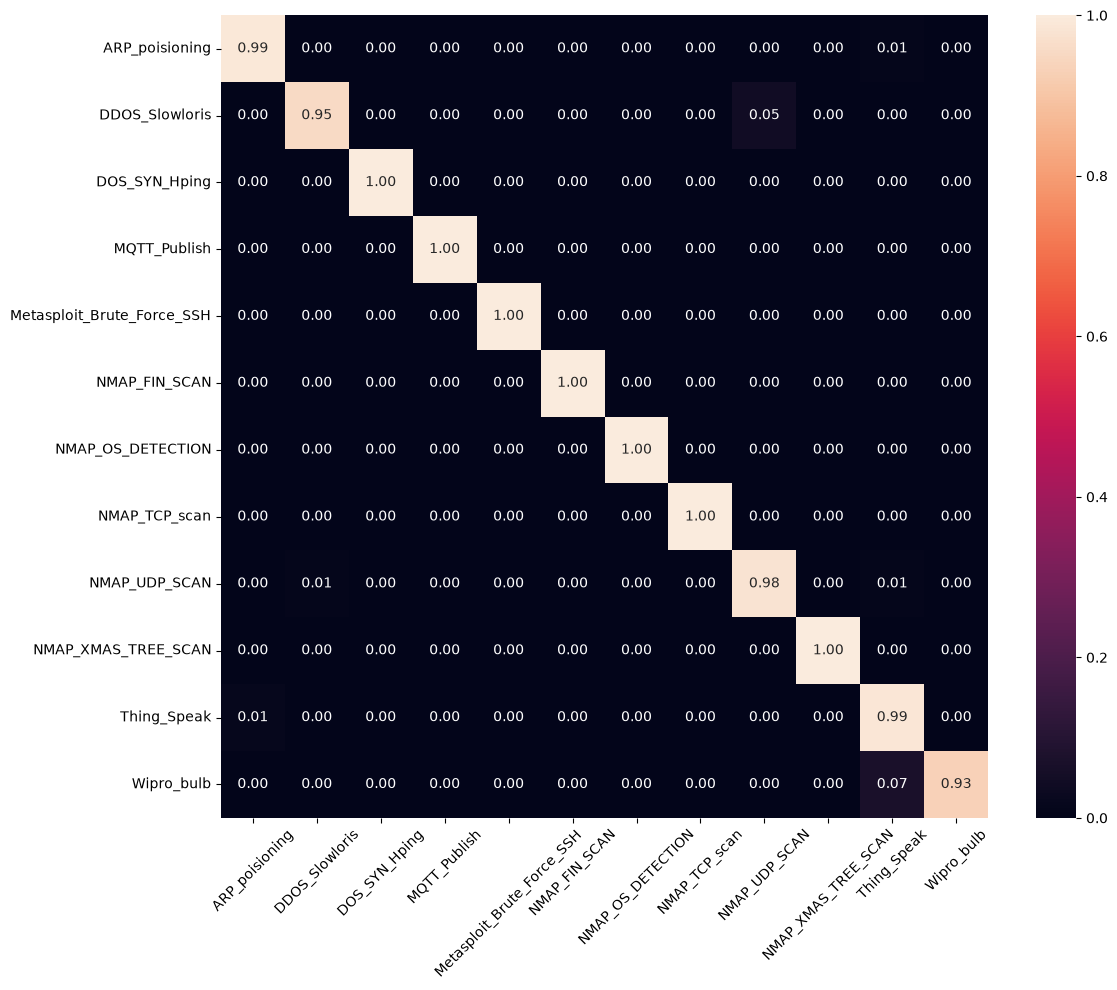

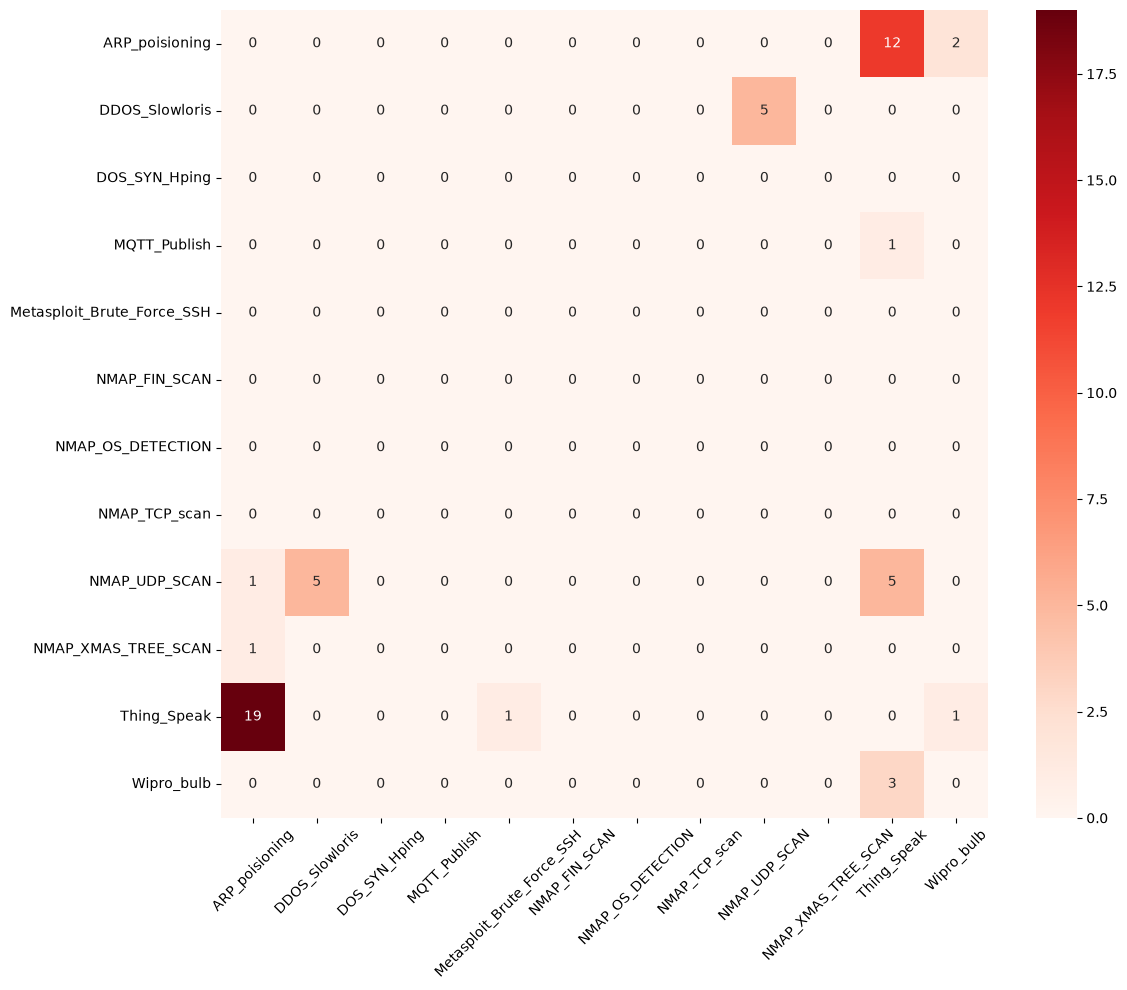

,macro_f1,Wipro_bulb,DDOS_Slowloris,Metasploit_Brute_Force_SSH,NMAP_FIN_SCAN
0.025,0.964130,0.851064,0.909091,1.0,1.0
0.975,0.991174,1.000000,0.990099,1.0,1.0


In [9]:
# Báo cáo lớp, bootstrap khoảng tin cậy và hình test
final_pred=test_preds[chosen.model]; labels=sorted(y.unique()); pr,rc,f1,sup=precision_recall_fscore_support(y_test,final_pred,labels=labels,zero_division=0); report=pd.DataFrame({'class':labels,'precision':pr,'recall':rc,'f1':f1,'support':sup}); display(report)
cm=confusion_matrix(y_test,final_pred,labels=labels); norm=cm/cm.sum(axis=1,keepdims=True); plt.figure(figsize=(12,10)); sns.heatmap(norm,annot=True,fmt='.2f',vmin=0,vmax=1,xticklabels=labels,yticklabels=labels); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig('../figures/final_test_confusion_normalized_test.png',dpi=150); plt.show(); err=cm.copy(); np.fill_diagonal(err,0); plt.figure(figsize=(12,10)); sns.heatmap(err,annot=True,fmt='d',cmap='Reds',xticklabels=labels,yticklabels=labels); plt.xticks(rotation=45); plt.tight_layout(); plt.savefig('../figures/final_test_confusion_errors_test.png',dpi=150); plt.show()
rng=np.random.default_rng(42); boot=[]; rare=['Wipro_bulb','DDOS_Slowloris','Metasploit_Brute_Force_SSH','NMAP_FIN_SCAN']; yt=np.asarray(y_test); yp=np.asarray(final_pred)
for _ in range(1000):
    idx=rng.integers(0,len(yt),len(yt)); boot.append([f1_score(yt[idx],yp[idx],average='macro',zero_division=0)]+list(recall_score(yt[idx],yp[idx],labels=rare,average=None,zero_division=0)))
ci=pd.DataFrame(boot,columns=['macro_f1']+rare).quantile([.025,.975]); display(ci)

Bootstrap lấy lại các cặp nhãn thật/dự đoán 1000 lần, không huấn luyện lại. Các lớp hiếm chỉ có khoảng 6–7 mẫu test nên khoảng tin cậy của recall không ổn định.

In [10]:
# Tổng kết cuối Giai đoạn 5
final_metric=test_table[test_table.model==chosen.model].iloc[0]; cv_value=chosen.macro_f1_mean; diff=final_metric.macro_f1_mean-cv_value; low_class=report.loc[report.recall.idxmin(),'class']; print('=== TỔNG KẾT GIAI ĐOẠN 5 ==='); print(f'Mô hình cuối: {chosen.model}; lý do: {reason}'); print(f'Macro-F1 test={final_metric.macro_f1_mean:.6f}; CI95%=[{ci.loc[0.025,"macro_f1"]:.6f},{ci.loc[0.975,"macro_f1"]:.6f}].'); print(f'Chênh test-CV={diff:.6f}.'); print(f'Lớp recall thấp nhất test: {low_class}, recall={report.loc[report.recall.idxmin(),"recall"]:.6f}.'); print(f'RQ2: RF CV Macro-F1={cv_table.loc[cv_table.model=="RandomForest_tuned","macro_f1_mean"].iloc[0]:.6f}; DT CV={cv_table.loc[cv_table.model=="DecisionTree_tuned","macro_f1_mean"].iloc[0]:.6f}; MLP CV={cv_table.loc[cv_table.model=="MLP_tuned","macro_f1_mean"].iloc[0]:.6f}; kết luận dựa trên CV train.')

=== TỔNG KẾT GIAI ĐOẠN 5 ===
Mô hình cuối: RandomForest_tuned; lý do: Macro-F1 CV cao nhất và chênh mô hình kế tiếp=0.008560.
Macro-F1 test=0.981320; CI95%=[0.964130,0.991174].
Chênh test-CV=0.024064.
Lớp recall thấp nhất test: Wipro_bulb, recall=0.931818.
RQ2: RF CV Macro-F1=0.957256; DT CV=0.948696; MLP CV=0.943973; kết luận dựa trên CV train.
